# 01 — Exploração e limpeza dos dados

**Projeto Integrador:** Predição de Churn em Clientes de Telecomunicações utilizando Machine Learning

Este caderno corresponde às **Etapas 1 a 3** do projeto:

1. conhecer o conjunto de dados;
2. realizar a análise exploratória (relações com o *churn*);
3. limpar e tratar inconsistências, em especial a variável `TotalCharges`.

O objetivo, neste momento, **não** é treinar modelos. É entender os dados o suficiente para preparar, com segurança, a modelagem do caderno `02_modelagem.ipynb`.

## Configuração inicial

In [3]:
%matplotlib inline
from pathlib import Path
import os

# Garante execução a partir da raiz do projeto, tanto no Jupyter
# (quando o caderno é aberto em notebooks/) quanto via nbconvert.
raiz = Path.cwd()
if not (raiz / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
    candidata = raiz / ".." if raiz.name == "notebooks" else raiz.parent
    candidata = candidata.resolve()
    if (candidata / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv").exists():
        os.chdir(candidata)

print("Diretório de trabalho:", Path.cwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Estilo simples e reproduzível dos gráficos
plt.rcParams.update({
    "figure.figsize": (8, 4.8),
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

COR_NO = "#4C78A8"
COR_YES = "#E45756"
COR_DESTAQUE = "#F58518"


Diretório de trabalho: /Users/joaogabriel/Downloads/telco-churn


## Etapa 1 — Conhecer os dados

Carregamos o arquivo clássico *Telco Customer Churn* e executamos as inspeções recomendadas no enunciado do projeto.

In [4]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

### Respostas da Etapa 1

**Quantos clientes existem?**
Existem **7.043 clientes** (linhas) no conjunto de dados.

**Quantas variáveis existem?**
Existem **21 variáveis** (colunas). Entre elas estão o identificador do cliente (`customerID`) e a variável-alvo (`Churn`). As demais 19 colunas são candidatas a variáveis preditivas.

**Quais variáveis são numéricas?**
Pelo tipo armazenado no arquivo:

- `SeniorCitizen` (`int64`) — indicador binário 0/1 (conceitualmente categórica);
- `tenure` (`int64`) — tempo de permanência, em meses;
- `MonthlyCharges` (`float64`) — valor cobrado mensalmente.

A variável `TotalCharges` **aparece como texto** (`str`/`object`), embora represente um valor monetário. Ela precisará ser convertida para numérica na Etapa 3.

**Quais são categóricas?**
São categóricas (texto ou categorias): `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod` e a própria `Churn`. O campo `customerID` também é textual, mas é apenas um identificador — **não deve ser usado como variável preditiva**.

**Existem valores ausentes ou inconsistentes?**
O `df.info()` e o `isnull()` inicial não apontam valores `NaN`. Contudo, isso **não significa que os dados estejam íntegros**. `TotalCharges` está como texto e contém **11 registros em branco** (espaços), todos com `tenure = 0`. Essa inconsistência só fica visível depois da conversão para numérico e será tratada de forma consciente na Etapa 3.

**Como está distribuído o churn?**

| Churn | Frequência | Proporção |
| ----- | ---------: | --------: |
| No    | 5.174      | 73,46%    |
| Yes   | 1.869      | 26,54%    |

A classe positiva (*churn*) é **minoria**. Um modelo que previsse sempre “não sai” acertaria cerca de 73% dos casos (*accuracy*) e, ainda assim, falharia em identificar justamente os clientes que cancelam. Por isso, nas etapas de modelagem, precisamos olhar além da acurácia — em especial *recall* da classe *Churn* e F1-score.

## Etapa 2 — Análise exploratória

Foram escolhidas **seis análises** ligadas à hipótese do projeto: contrato, tempo de permanência, valor mensal, serviço de internet, suporte técnico e forma de pagamento.

Para cada gráfico, respondemos: *“O que esse resultado parece indicar?”*

### 2.1 Contrato × Churn

Contagens:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48

Taxa de churn por tipo de contrato:
Contract
Month-to-month    42.71%
One year          11.27%
Two year           2.83%
Name: Yes, dtype: str


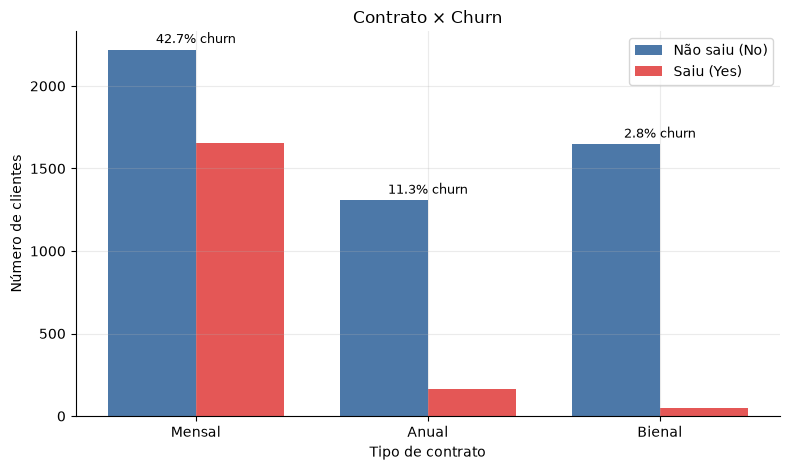

In [10]:
contrato_counts = pd.crosstab(df["Contract"], df["Churn"])
contrato_rate = pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100

ordem_contrato = ["Month-to-month", "One year", "Two year"]
contrato_counts = contrato_counts.loc[ordem_contrato]
contrato_rate = contrato_rate.loc[ordem_contrato]

print("Contagens:")
print(contrato_counts)
print("\nTaxa de churn por tipo de contrato:")
print(contrato_rate.round(2).astype(str) + "%")

fig, ax = plt.subplots()
x = np.arange(len(ordem_contrato))
largura = 0.38
ax.bar(x - largura / 2, contrato_counts["No"], width=largura, label="Não saiu (No)", color=COR_NO)
ax.bar(x + largura / 2, contrato_counts["Yes"], width=largura, label="Saiu (Yes)", color=COR_YES)
ax.set_xticks(x)
ax.set_xticklabels(["Mensal", "Anual", "Bienal"])
ax.set_ylabel("Número de clientes")
ax.set_xlabel("Tipo de contrato")
ax.set_title("Contrato × Churn")
ax.legend()
for i, taxa in enumerate(contrato_rate):
    topo = max(contrato_counts.iloc[i]["No"], contrato_counts.iloc[i]["Yes"])
    ax.annotate(f"{taxa:.1f}% churn", (x[i], topo + 40), ha="center", fontsize=9)
plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

O tipo de contrato tem associação muito forte com o cancelamento. Clientes com contrato **mês a mês** apresentam taxa de *churn* de **42,7%** (1.655 de 3.875). No contrato de **um ano**, a taxa cai para **11,3%** e, no de **dois anos**, para apenas **2,8%**.

Isso não prova, por si só, que o contrato *cause* a permanência (clientes já satisfeitos podem escolher prazos mais longos). Ainda assim, o padrão é compatível com a hipótese do projeto: o tipo de contrato é uma característica relevante para estimar o risco de *churn*.

### 2.2 Tempo como cliente (*tenure*) × Churn

        count   mean    std  min   25%   50%   75%   max
Churn                                                   
No     5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0


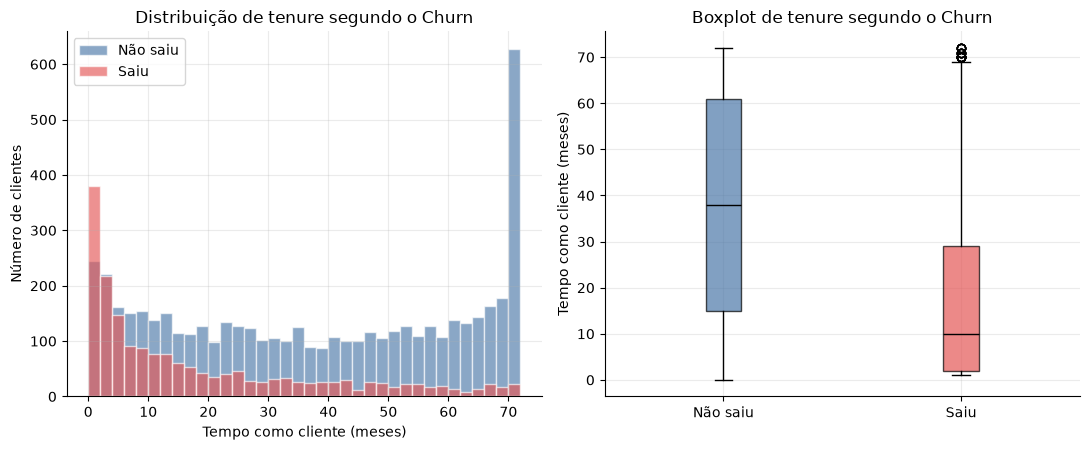

In [11]:
print(df.groupby("Churn")["tenure"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for rotulo, cor, nome in [("No", COR_NO, "Não saiu"), ("Yes", COR_YES, "Saiu")]:
    axes[0].hist(
        df.loc[df["Churn"] == rotulo, "tenure"],
        bins=range(0, 74, 2),
        alpha=0.65,
        label=nome,
        color=cor,
        edgecolor="white",
    )
axes[0].set_xlabel("Tempo como cliente (meses)")
axes[0].set_ylabel("Número de clientes")
axes[0].set_title("Distribuição de tenure segundo o Churn")
axes[0].legend()

dados_box = [
    df.loc[df["Churn"] == "No", "tenure"],
    df.loc[df["Churn"] == "Yes", "tenure"],
]
bp = axes[1].boxplot(dados_box, tick_labels=["Não saiu", "Saiu"], patch_artist=True, medianprops={"color": "black"})
for patch, cor in zip(bp["boxes"], [COR_NO, COR_YES]):
    patch.set_facecolor(cor)
    patch.set_alpha(0.7)
axes[1].set_ylabel("Tempo como cliente (meses)")
axes[1].set_title("Boxplot de tenure segundo o Churn")

plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

Clientes que cancelaram estão, em média, há bem menos tempo na empresa: **17,98 meses**, contra **37,57 meses** entre os que permaneceram. A mediana reforça o contraste (10 versus 38 meses). Há um pico visível de cancelamentos nos primeiros meses de relacionamento.

O padrão sugere que o risco é mais alto no início da jornada do cliente. *Tenure* deve entrar no modelo como variável preditiva numérica. De novo, correlação não é causalidade: quem já está há muitos anos pode ser, também, um perfil historicamente mais estável.

### 2.3 Valor mensal (*MonthlyCharges*) × Churn

        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


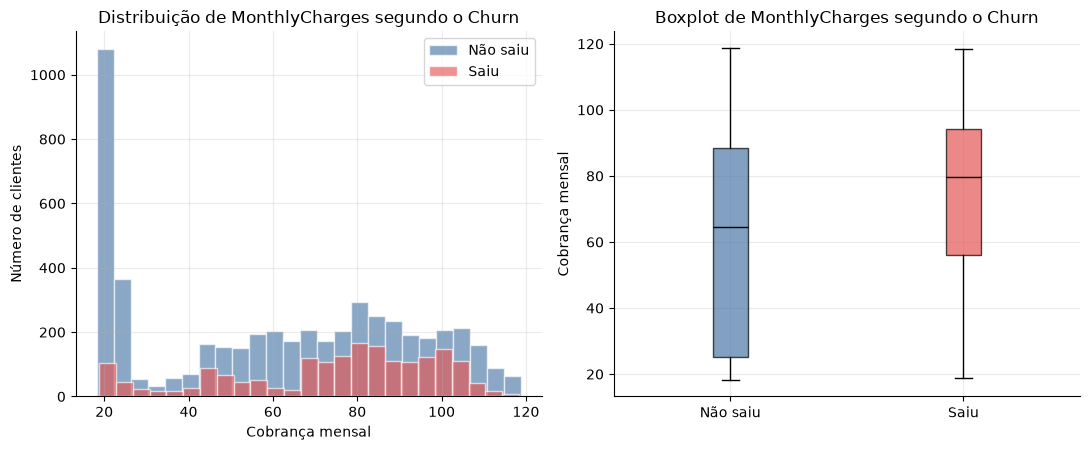

In [12]:
print(df.groupby("Churn")["MonthlyCharges"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

for rotulo, cor, nome in [("No", COR_NO, "Não saiu"), ("Yes", COR_YES, "Saiu")]:
    axes[0].hist(
        df.loc[df["Churn"] == rotulo, "MonthlyCharges"],
        bins=25,
        alpha=0.65,
        label=nome,
        color=cor,
        edgecolor="white",
    )
axes[0].set_xlabel("Cobrança mensal")
axes[0].set_ylabel("Número de clientes")
axes[0].set_title("Distribuição de MonthlyCharges segundo o Churn")
axes[0].legend()

dados_box = [
    df.loc[df["Churn"] == "No", "MonthlyCharges"],
    df.loc[df["Churn"] == "Yes", "MonthlyCharges"],
]
bp = axes[1].boxplot(dados_box, tick_labels=["Não saiu", "Saiu"], patch_artist=True, medianprops={"color": "black"})
for patch, cor in zip(bp["boxes"], [COR_NO, COR_YES]):
    patch.set_facecolor(cor)
    patch.set_alpha(0.7)
axes[1].set_ylabel("Cobrança mensal")
axes[1].set_title("Boxplot de MonthlyCharges segundo o Churn")

plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

Quem cancelou paga, em média, **mais por mês**: **US$ 74,44** contra **US$ 61,27** entre os que ficaram. A mediana também é mais alta no grupo de *churn* (79,65 versus 64,43).

Há uma concentração de clientes fiéis em faturas mais baixas (planos mais simples ou apenas telefone). Valores mensais elevados, muitas vezes associados a fibra e a vários adicionais, aparecem com mais frequência entre os que saem. O preço isolado não “explica” o cancelamento, mas o padrão é coerente com a hipótese de que o valor cobrado ajuda a estimar o risco.

### 2.4 Serviço de internet × Churn

Contagens:
Churn              No   Yes
InternetService            
Fiber optic      1799  1297
DSL              1962   459
No               1413   113

Taxa de churn por tipo de internet:
InternetService
Fiber optic    41.89%
DSL            18.96%
No               7.4%
Name: Yes, dtype: str


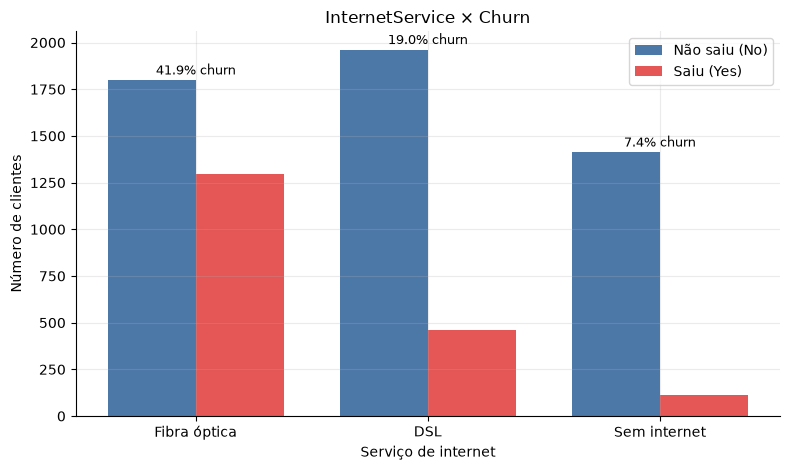

In [13]:
internet_counts = pd.crosstab(df["InternetService"], df["Churn"])
internet_rate = pd.crosstab(df["InternetService"], df["Churn"], normalize="index")["Yes"] * 100

ordem_internet = ["Fiber optic", "DSL", "No"]
internet_counts = internet_counts.loc[ordem_internet]
internet_rate = internet_rate.loc[ordem_internet]

print("Contagens:")
print(internet_counts)
print("\nTaxa de churn por tipo de internet:")
print(internet_rate.round(2).astype(str) + "%")

fig, ax = plt.subplots()
x = np.arange(len(ordem_internet))
largura = 0.38
ax.bar(x - largura / 2, internet_counts["No"], width=largura, label="Não saiu (No)", color=COR_NO)
ax.bar(x + largura / 2, internet_counts["Yes"], width=largura, label="Saiu (Yes)", color=COR_YES)
ax.set_xticks(x)
ax.set_xticklabels(["Fibra óptica", "DSL", "Sem internet"])
ax.set_ylabel("Número de clientes")
ax.set_xlabel("Serviço de internet")
ax.set_title("InternetService × Churn")
ax.legend()
for i, taxa in enumerate(internet_rate):
    topo = max(internet_counts.iloc[i]["No"], internet_counts.iloc[i]["Yes"])
    ax.annotate(f"{taxa:.1f}% churn", (x[i], topo + 30), ha="center", fontsize=9)
plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

A taxa de *churn* é bem mais alta entre clientes de **fibra óptica (41,9%)** do que entre clientes de **DSL (19,0%)**. Quem **não possui internet** cancela bem menos (**7,4%**).

Uma leitura possível é a combinação de preço mais alto da fibra com expectativas de qualidade/atendimento. Não podemos afirmar que “fibra causa cancelamento”: o serviço pode estar correlacionado com fatura maior e com contratos mensais. De qualquer forma, `InternetService` é uma variável discriminante e deve ser considerada no modelo.

### 2.5 Suporte técnico × Churn

Contagens:
Churn                  No   Yes
TechSupport                    
No                   2027  1446
Yes                  1734   310
No internet service  1413   113

Taxa de churn por suporte técnico:
TechSupport
No                     41.64%
Yes                    15.17%
No internet service      7.4%
Name: Yes, dtype: str


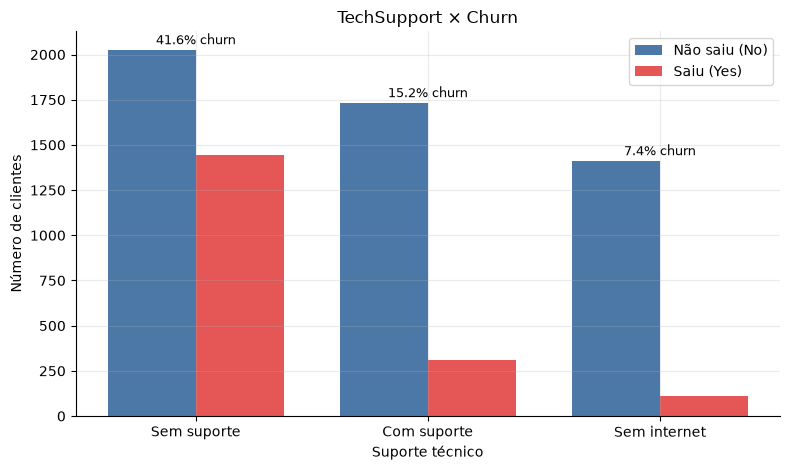

In [14]:
suporte_counts = pd.crosstab(df["TechSupport"], df["Churn"])
suporte_rate = pd.crosstab(df["TechSupport"], df["Churn"], normalize="index")["Yes"] * 100

ordem_suporte = ["No", "Yes", "No internet service"]
suporte_counts = suporte_counts.loc[ordem_suporte]
suporte_rate = suporte_rate.loc[ordem_suporte]

print("Contagens:")
print(suporte_counts)
print("\nTaxa de churn por suporte técnico:")
print(suporte_rate.round(2).astype(str) + "%")

fig, ax = plt.subplots()
x = np.arange(len(ordem_suporte))
largura = 0.38
ax.bar(x - largura / 2, suporte_counts["No"], width=largura, label="Não saiu (No)", color=COR_NO)
ax.bar(x + largura / 2, suporte_counts["Yes"], width=largura, label="Saiu (Yes)", color=COR_YES)
ax.set_xticks(x)
ax.set_xticklabels(["Sem suporte", "Com suporte", "Sem internet"])
ax.set_ylabel("Número de clientes")
ax.set_xlabel("Suporte técnico")
ax.set_title("TechSupport × Churn")
ax.legend()
for i, taxa in enumerate(suporte_rate):
    topo = max(suporte_counts.iloc[i]["No"], suporte_counts.iloc[i]["Yes"])
    ax.annotate(f"{taxa:.1f}% churn", (x[i], topo + 30), ha="center", fontsize=9)
plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

Clientes de internet **sem suporte técnico** têm taxa de *churn* de **41,6%**, enquanto quem **contrata o suporte** apresenta **15,2%**. O grupo “sem internet” repete os 7,4% já vistos.

O padrão é semelhante ao de outros adicionais de segurança (`OnlineSecurity`, por exemplo). Ter suporte pode indicar tanto um serviço que reduz problemas quanto um cliente mais “amarrado” ao pacote. Para o modelo, a mensagem prática é clara: a ausência de suporte técnico, entre quem tem internet, está associada a risco bem mais elevado.

### 2.6 Método de pagamento × Churn

Contagens:
Churn                        No   Yes
PaymentMethod                        
Electronic check           1294  1071
Mailed check               1304   308
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232

Taxa de churn por método de pagamento:
PaymentMethod
Electronic check             45.29%
Mailed check                 19.11%
Bank transfer (automatic)    16.71%
Credit card (automatic)      15.24%
Name: Yes, dtype: str


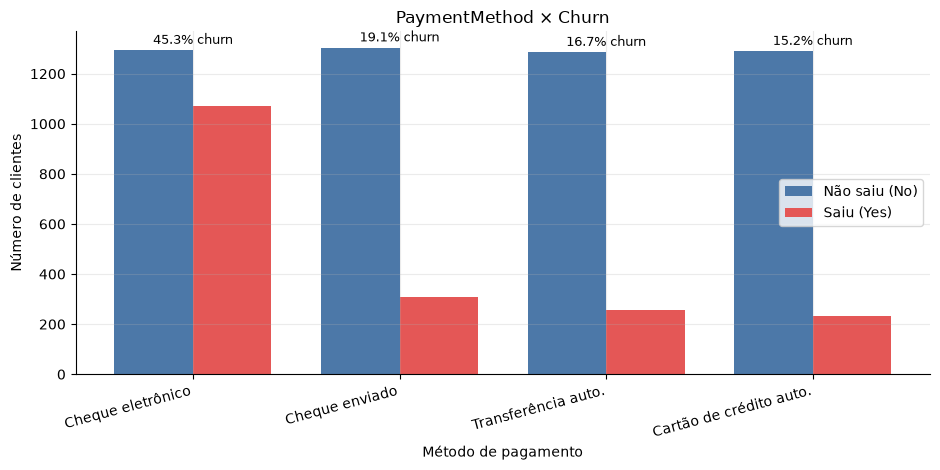

In [15]:
pagto_counts = pd.crosstab(df["PaymentMethod"], df["Churn"])
pagto_rate = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")["Yes"] * 100

ordem_pagto = [
    "Electronic check",
    "Mailed check",
    "Bank transfer (automatic)",
    "Credit card (automatic)",
]
pagto_counts = pagto_counts.loc[ordem_pagto]
pagto_rate = pagto_rate.loc[ordem_pagto]

print("Contagens:")
print(pagto_counts)
print("\nTaxa de churn por método de pagamento:")
print(pagto_rate.round(2).astype(str) + "%")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(ordem_pagto))
largura = 0.38
ax.bar(x - largura / 2, pagto_counts["No"], width=largura, label="Não saiu (No)", color=COR_NO)
ax.bar(x + largura / 2, pagto_counts["Yes"], width=largura, label="Saiu (Yes)", color=COR_YES)
ax.set_xticks(x)
ax.set_xticklabels(
    ["Cheque eletrônico", "Cheque enviado", "Transferência auto.", "Cartão de crédito auto."],
    rotation=15,
    ha="right",
)
ax.set_ylabel("Número de clientes")
ax.set_xlabel("Método de pagamento")
ax.set_title("PaymentMethod × Churn")
ax.legend()
for i, taxa in enumerate(pagto_rate):
    topo = max(pagto_counts.iloc[i]["No"], pagto_counts.iloc[i]["Yes"])
    ax.annotate(f"{taxa:.1f}% churn", (x[i], topo + 25), ha="center", fontsize=9)
plt.tight_layout()
plt.show()


**O que esse resultado parece indicar?**

O **cheque eletrônico** se destaca negativamente: **45,3%** de *churn*, bem acima dos demais métodos — cheque enviado (19,1%), transferência automática (16,7%) e cartão de crédito automático (15,2%).

Pagamentos automáticos estão associados a maior permanência, o que pode refletir tanto conveniência quanto um vínculo mais estável com a operadora. Já o cheque eletrônico concentra uma fatia desproporcional dos cancelamentos (1.071 dos 1.869 casos de *churn*). Essa variável também deve integrar o modelo.

### Síntese da análise exploratória

Os padrões observados são coerentes com a hipótese do projeto. Em resumo, o risco de *churn* aparece mais associado a:

- contrato **mês a mês**;
- **pouco tempo** de relacionamento;
- **fatura mensal mais alta**;
- internet de **fibra óptica**;
- **ausência de suporte técnico** (entre quem tem internet);
- pagamento por **cheque eletrônico**.

Esses resultados guiam a interpretação do modelo e da aplicação, mas **não autorizam afirmações causais** nem recomendações comerciais automáticas.

## Etapa 3 — Limpeza, com atenção a `TotalCharges`

A variável `TotalCharges` deveria ser numérica, mas chegou como texto. O enunciado pede a conversão com `errors="coerce"` e, em seguida, uma decisão **consciente** sobre as linhas afetadas — nunca apagar dados sem saber quantos registros serão perdidos.

In [16]:
print("Tipo original de TotalCharges:", df["TotalCharges"].dtype)
print("Valores nulos declarados (antes da conversão):", int(df["TotalCharges"].isna().sum()))

# Espaços em branco ou strings vazias não aparecem como NaN enquanto o tipo é texto
n_em_branco = (df["TotalCharges"].astype(str).str.strip() == "").sum()
print("Registros com TotalCharges em branco (texto vazio ou só espaço):", int(n_em_branco))

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("\nTipo após pd.to_numeric(..., errors='coerce'):", df["TotalCharges"].dtype)

print("\nValores ausentes por coluna depois da conversão:")
print(df.isnull().sum())


Tipo original de TotalCharges: str
Valores nulos declarados (antes da conversão): 0
Registros com TotalCharges em branco (texto vazio ou só espaço): 11

Tipo após pd.to_numeric(..., errors='coerce'): float64

Valores ausentes por coluna depois da conversão:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [17]:
linhas_afetadas = df[df["TotalCharges"].isna()].copy()
print("Quantidade de linhas afetadas:", len(linhas_afetadas))
print("Proporção da base:", f"{100 * len(linhas_afetadas) / len(df):.2f}%")
print("\nDetalhe das linhas afetadas:")
print(linhas_afetadas[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]].to_string(index=True))
print("\nTenure das linhas afetadas (valores únicos):", sorted(linhas_afetadas["tenure"].unique()))
print("Churn das linhas afetadas:")
print(linhas_afetadas["Churn"].value_counts())


Quantidade de linhas afetadas: 11
Proporção da base: 0.16%

Detalhe das linhas afetadas:
      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No

Tenure das linhas afetadas (valores únicos): [np.int64(0)]
Churn das linhas afetadas:
Churn
No    11
Name: count, dtype: int64


### Decisão de tratamento e justificativa

Foram afetados **11 registros**, o equivalente a **0,16%** da base (11 de 7.043). Em **todos** eles:

- `tenure` é igual a **0** (cliente recém-chegado, ainda sem um mês completo);
- `TotalCharges` estava em branco;
- `Churn` é **No** (nenhum desses 11 havia cancelado).

A leitura mais razoável é operacional, e não um erro aleatório: se o cliente ainda não completou um ciclo de faturamento, o valor acumulado **ainda não existe**. Nesse caso, preencher `TotalCharges` com **0** é coerente com o significado da variável.

**Por que não simplesmente apagar as 11 linhas?**
Embora 0,16% seja pouco, excluir registros sem necessidade descarta clientes válidos e, neste caso, removeria apenas exemplos da classe majoritária. Como conhecemos o motivo do branco, a imputação por zero é mais fiel ao fenômeno do que a exclusão.

**Por que não usar a mediana (cerca de 1.400)?**
A mediana representaria um cliente “médio”, com muitos meses de fatura. Aplicá-la a quem tem `tenure = 0` criaria uma incoerência (total alto com tempo zero) e poderia atrapalhar o aprendizado do modelo.

A conversão e o preenchimento com zero são aplicados a seguir. O *pipeline* da modelagem ainda terá um *imputer* como rede de segurança, caso algum valor ausente apareça no uso futuro da aplicação.

In [18]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Valores ausentes restantes em TotalCharges:", int(df["TotalCharges"].isna().sum()))
print("Valores ausentes totais no DataFrame:", int(df.isnull().sum().sum()))
print("\nDescritivas de TotalCharges após o tratamento:")
print(df["TotalCharges"].describe().round(2))
print("\nConferência: TotalCharges dos clientes com tenure = 0")
print(df.loc[df["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])


Valores ausentes restantes em TotalCharges: 0
Valores ausentes totais no DataFrame: 0

Descritivas de TotalCharges após o tratamento:
count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: TotalCharges, dtype: float64

Conferência: TotalCharges dos clientes com tenure = 0
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           0.0    No
753        0           20.25           0.0    No
936        0           80.85           0.0    No
1082       0           25.75           0.0    No
1340       0           56.05           0.0    No
3331       0           19.85           0.0    No
3826       0           25.35           0.0    No
4380       0           20.00           0.0    No
5218       0           19.70           0.0    No
6670       0           73.35           0.0    No
6754       0           61.90           0.0    No


## Encerramento da exploração

Ao final desta etapa:

- conhecemos o tamanho da base (**7.043 × 21**), os tipos de variáveis e o desbalanceamento do *churn* (**26,54%** de cancelamentos);
- identificamos padrões relevantes em contrato, *tenure*, fatura mensal, internet, suporte técnico e pagamento;
- tratamos `TotalCharges` de forma documentada, afetando **11 linhas** (preenchidas com zero).

O caderno `02_modelagem.ipynb` parte destes mesmos critérios de limpeza para preparar as variáveis, treinar três modelos, compará-los e salvar o *pipeline* completo.